# Rainbow line profiler — minimal notebook prototype

This notebook is the smallest possible prototype for checking the analysis loop in Jupyter.
It reuses the existing project code and starts with a fixed line on the demo image.

For the first pass, edit the line coordinates in the parameter cell and rerun the analysis cells.


## Initialization

### Importing functions from the src/ folders
Simple functions to do the analysis reusing code for the online app

### Loading modules and demo image

In [1]:
# src is importable via editable install (pip install -e .); no sys.path hack needed
from pathlib import Path

import numpy as np
import plotly.graph_objects as go
from PIL import Image

from src.analysis.color import normalize_rgb, rgb_to_hsv_unwrapped
from src.analysis.rainbow import compare_profiles, generate_reference_profile
from src.analysis.sampling import compute_distances, sample_line_rgb
from src.config import load_config

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
config = load_config()
demo_path = ROOT / config["demo"]["path"]
image = Image.open(demo_path).convert("RGB")
rgb = np.asarray(image)
h, w = rgb.shape[:2]
print(f"Loaded: {demo_path}")
print(f"Image size: {w} x {h}")


Loaded: /Users/joshua/git/rainbower/assets/demo/Ring-billed_gull_and_a_rainbow_(52910).jpg
Image size: 1280 x 960


### Setting line parameters

In [2]:
# Line endpoints in image coordinates: (x, y)
start = (120, 180)
end = (980, 250)
linewidth = config["app"]["default_line_width"]

assert 0 <= start[0] < w and 0 <= start[1] < h
assert 0 <= end[0] < w and 0 <= end[1] < h
print("start =", start, "end =", end, "linewidth =", linewidth)

start = (120, 180) end = (980, 250) linewidth = 5


### Previws of the canvas with the line on top

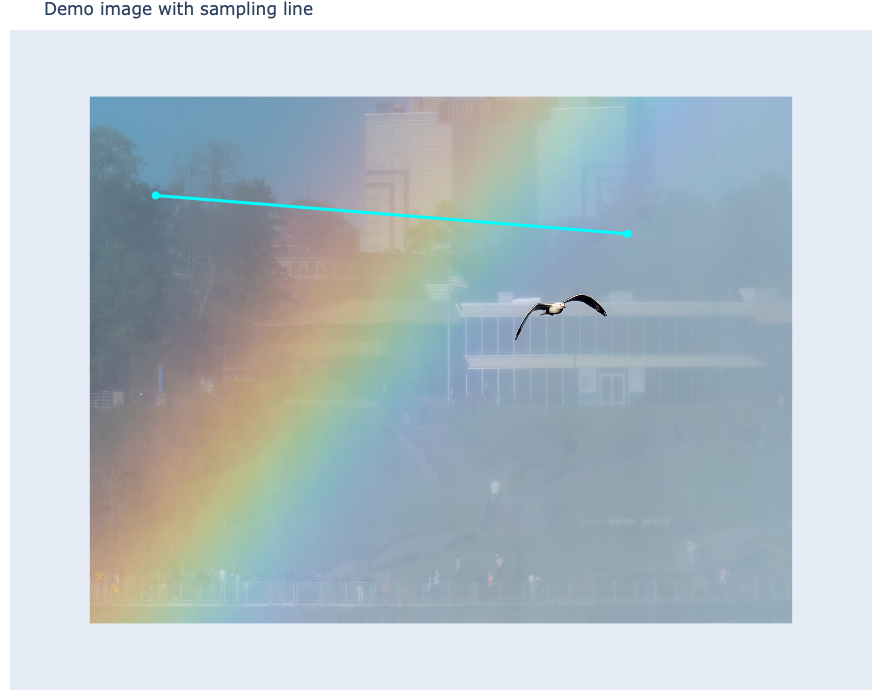

In [3]:
fig = go.Figure()
fig.add_layout_image(
    dict(
        source=image,
        x=0,
        y=0,
        sizex=w,
        sizey=h,
        xref="x",
        yref="y",
        sizing="stretch",
        layer="below",
    )
)
fig.add_trace(
    go.Scatter(
        x=[start[0], end[0]],
        y=[start[1], end[1]],
        mode="lines+markers",
        line=dict(color="cyan", width=3),
        marker=dict(size=8, color="cyan"),
        name="sample line",
    )
)
fig.update_xaxes(range=[0, w], visible=False)
fig.update_yaxes(range=[h, 0], visible=False, scaleanchor="x")
fig.update_layout(
    width=min(w, 1100),
    height=min(h, 700),
    margin=dict(l=10, r=10, t=30, b=10),
    title="Demo image with sampling line",
)
fig.show()

#### Misc image info

In [4]:
src = (start[1], start[0])
dst = (end[1], end[0])
sampled_rgb = sample_line_rgb(rgb, src=src, dst=dst, linewidth=linewidth)
distance = compute_distances(src, dst, len(sampled_rgb))
rgb01 = normalize_rgb(sampled_rgb)
hue, saturation, value = rgb_to_hsv_unwrapped(rgb01)
reference = generate_reference_profile(len(sampled_rgb), config)
comparison = compare_profiles(
    measured={"hue": hue, "saturation": saturation},
    reference=reference,
)
comparison

{'hue_correlation': 0.9807292328851486,
 'saturation_difference': 0.4137750695327898,
 'monotonicity': 0.7786790266512167,
 'overall_score': np.float64(0.8219679009129807),
 'label': 'Profile is reasonably consistent with an idealized rainbow signal.'}

### Simulated line profile

Simulating a basic rainbow using simple overlapped gausian distributions

In [5]:
def simulated_rainbow_profile(num_points=500):
    position = np.linspace(0, 1, num_points)
    sky = 1 / (1 + np.exp(-12 * (position - 0.55)))

    base_red = 0.20 + 0.25 * sky
    base_green = 0.40 + 0.20 * sky
    base_blue = 0.70 + 0.15 * sky

    def gaussian(mean, amplitude, standard_deviation):
        return amplitude * np.exp(-((position - mean) ** 2) / (2 * standard_deviation**2))

    return np.column_stack((
        position,
        base_red + gaussian(0.38, 0.40, 0.06),
        base_green + gaussian(0.48, 0.30, 0.07),
        base_blue + gaussian(0.56, 0.15, 0.08),
    )).clip(0, 1)

In [6]:
profile = simulated_rainbow_profile(num_points=len(distance))
position = distance
simulated_position = np.clip(position, position.min(), position.max())
channel_names = ["Red", "Green", "Blue"]
colors = config["plots"]["rgb_colors"]

fig = go.Figure()
for i, color in enumerate(colors):
    fig.add_trace(go.Scatter(
        x=simulated_position,
        y=np.clip(profile[:, i + 1], 0, 1),
        mode="lines",
        name=f"Simulated {channel_names[i]}",
        line=dict(color=color, dash="dot"),
        ))

# Static rendering disabled; use the interactive plot below.


## Sample and profile

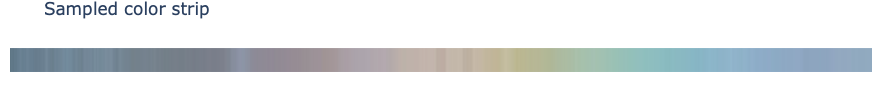

In [7]:
strip = np.repeat(rgb01[np.newaxis, :, :], 24, axis=0)
fig = go.Figure(go.Image(z=(strip * 255).astype(np.uint8)))
fig.update_layout(height=100, margin=dict(l=10, r=10, t=30, b=10), title="Sampled color strip")
fig.update_xaxes(showticklabels=False)
fig.update_yaxes(showticklabels=False)

### Code

In [8]:
def overlay_figures(base_fig, *figures):
    combined = go.Figure(base_fig)

    for figure in figures:
        combined.add_traces(list(figure.data))

    return combined

def rgb_trace(x, y, name, color, dash="solid"):
    return go.Scatter(
        x=x,
        y=y,
        name=name,
        mode="lines",
        line={"color": color, "dash": dash},
    )

fig = go.Figure()

for i, color in enumerate(colors):
    fig.add_trace(rgb_trace(
        distance,
        rgb01[:, i],
        f"Measured {channel_names[i]}",
        color,
        dash="solid",
    ))
    fig.add_trace(rgb_trace(
        simulated_position,
        profile[:, i + 1],
        f"Simulated {channel_names[i]}",
        color,
        dash="dot",
    ))

### Interactive plot

The idea would be to let the user have sliders to play around with the simulated parametsrs to achiever a good-enough coorelation with the RBG data from pixels to demonstrate the existance of a rainbow.

In [9]:
import ipywidgets as widgets
from IPython.display import clear_output, display


def interactive_profile(shift=0.0, scale=1.0):
    profile = simulated_rainbow_profile(num_points=len(rgb01))
    simulated_position = np.clip(
        distance + shift, distance.min(), distance.max()
    )

    fig = go.Figure()
    for i, color in enumerate(colors):
        fig.add_trace(rgb_trace(
            distance, rgb01[:, i], f"Measured {channel_names[i]}", color
        ))
        fig.add_trace(rgb_trace(
            simulated_position,
            np.clip(profile[:, i + 1] * scale, 0, 1),
            f"Simulated {channel_names[i]}",
            color,
            dash="dot",
        ))

    fig.update_layout(
        title="Interactive simulated vs. measured profile",
        xaxis_title="Position",
        yaxis_title="Intensity (0-1)",
    )
    return fig

shift_slider = widgets.FloatSlider(
    value=0.0, min=-100.0, max=100.0, step=1.0, description="Shift"
)
scale_slider = widgets.FloatSlider(
    value=1.0, min=0.5, max=1.5, step=0.05, description="Scale"
)
plot_output = widgets.Output()

def update_profile(change=None):
    with plot_output:
        clear_output(wait=True)
        display(interactive_profile(shift_slider.value, scale_slider.value))

shift_slider.observe(update_profile, names="value")
scale_slider.observe(update_profile, names="value")
display(widgets.VBox([shift_slider, scale_slider, plot_output]))
update_profile()